In [262]:
%load_ext autoreload
%autoreload 2
import numpy as np
import emcee
import corner
from matplotlib import pyplot as plt
from astropy import units as u
from astropy import constants as const
import time
from multiprocessing import Pool

from nfw_profile_heating import NFWProfile
from cluster_error_prop import Cluster_werr
from statistics_functions import log_lik
from load_data_and_var import load_data_and_var, generate_nfws_from_combined_dataset_werr
from plotting import savefig, paper_plot

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [155]:
from asymmetric_uncertainty_mod import a_u

In [156]:
a_u(3, pos_err=0.3, neg_err=0.2)


In [4]:
dataset, variances = load_data_and_var()

In [171]:
start_time = time.time()
nfws_werr = generate_nfws_from_combined_dataset_werr(dataset, variances)
end_time = time.time()
execution_time = end_time - start_time
print(execution_time)

31.298364877700806


In [248]:
len(nfws_werr)

188

In [158]:
nfws_subset = [nfw for nfw in nfws_werr if nfw.z < 0.2]#[:10]
#vars_subset = variances#[:10]
L_obs = np.array([nfw.L500.to(u.erg/u.s).value for nfw in nfws_subset])
variances_obs = np.array([nfw.L_err for nfw in nfws_subset])

In [159]:
[nfw.L_err for nfw in nfws_subset]

[0.1470371032047052,
 0.22761947095956636,
 0.09295868677236487,
 0.13354210223189256,
 0.33769969996773225,
 0.30620614226092835,
 0.046397015408826243,
 0.3303577981757954,
 0.17622325821980186,
 0.16410474517275686,
 0.24537675727893998,
 0.0784871898596615,
 0.09254886659399689,
 0.04290117582179533,
 0.014446791901477142,
 0.04427524236779235,
 0.05943654764724138,
 0.2867256713699701,
 0.4436884192992518,
 0.2681984406120019,
 0.09100651536661834,
 0.15513473211726408,
 0.09000598818961686,
 0.14363824973439615,
 0.05694014240691956,
 0.10325761146446223,
 0.5496809384801186,
 0.18113312845470245,
 0.09350518260762389,
 0.0690515036604239,
 0.09468265349291509,
 0.05805492920974524,
 0.06957019099946794,
 0.06425621151153067,
 0.09946722237715842,
 0.0871621217732997,
 0.2924042270393956,
 0.047541672740439966,
 0.1356420745535019,
 0.12071416594118309,
 0.3255298949531899,
 0.40327623441632665,
 0.3749006548866649,
 0.08836241223064706,
 0.022452047876462277,
 0.1450577097451025

In [226]:
start_time = time.time()
print(log_lik(p0, L_obs, nfws_subset, variances_obs))
end_time = time.time()
execution_time = end_time - start_time
print(execution_time)

-5.334799240896427
0.6186089515686035


In [225]:
import cProfile
import pstats

profiler = cProfile.Profile()
profiler.enable()

# Call the function
print(log_lik(p0, L_obs, nfws_subset, variances_obs))

profiler.disable()
stats = pstats.Stats(profiler).sort_stats('cumtime')
stats.print_stats()

-5.334799240896427
         320398 function calls in 0.782 seconds

   Ordered by: cumulative time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        2    0.000    0.000    0.781    0.391 /Users/eleanorstuart/opt/anaconda3/envs/idm/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3490(run_code)
        2    0.000    0.000    0.781    0.391 {built-in method builtins.exec}
        1    0.000    0.000    0.781    0.781 /var/folders/99/vfh56jrs1nqcj8zqtcs5fkv40000gn/T/ipykernel_18443/2650325478.py:1(<module>)
        1    0.000    0.000    0.781    0.781 /Users/eleanorstuart/Desktop/krisp/thermo-idm/statistics_functions.py:22(log_lik)
        1    0.001    0.001    0.781    0.781 /Users/eleanorstuart/Desktop/krisp/thermo-idm/statistics_functions.py:43(<listcomp>)
      154    0.005    0.000    0.780    0.005 /Users/eleanorstuart/Desktop/krisp/thermo-idm/cluster_error_prop.py:418(L500_analytic)
      154    0.026    0.000    0.763    0.005 /Users/e

In [130]:
profiler = cProfile.Profile()
profiler.enable()

# Call the function
print(nfws_subset[0].integrated_dm_cooling_rate_fast(1e-27, 1e-2))

profiler.disable()
stats = pstats.Stats(profiler).sort_stats('cumtime')
stats.print_stats()

1.0468848145728499e+43 (+1.6019986572969556e+42, -1.6100751034551884e+42)
         56806 function calls (56710 primitive calls) in 0.072 seconds

   Ordered by: cumulative time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        2    0.000    0.000    0.072    0.036 /Users/eleanorstuart/opt/anaconda3/envs/idm/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3490(run_code)
        2    0.000    0.000    0.072    0.036 {built-in method builtins.exec}
        1    0.000    0.000    0.072    0.072 /Users/eleanorstuart/Desktop/krisp/thermo-idm/cluster_error_prop.py:361(integrated_dm_cooling_rate_fast)
     1043    0.008    0.000    0.064    0.000 /Users/eleanorstuart/opt/anaconda3/envs/idm/lib/python3.11/site-packages/asymmetric_uncertainty/core.py:46(__init__)
     1044    0.009    0.000    0.056    0.000 /Users/eleanorstuart/opt/anaconda3/envs/idm/lib/python3.11/site-packages/numpy/core/numeric.py:2249(isclose)
      299    0.003    0.000    0.032

In [57]:
(u.Mpc**2).to(u.cm**2)

9.521406136918413e+48

9.521406136918413e+48

In [34]:
log_lik(p0, L_obs, vars_subset, nfws_subset)

-0.162579385359161

In [68]:
log_lik(p0, L_obs, nfws_subset)

-5.3347992408964275

In [35]:
p1 = [-30, -2]

In [75]:
log_lik(p1, L_obs, nfws_werr)

-7.97476444432926

In [162]:
log_sigma0s = range(-40, -24)
initial_conditions = [[s, -2] for s in log_sigma0s]

In [164]:
log_liks = [log_lik(p, L_obs, nfws_subset, variances_obs) for p in initial_conditions]

Text(0, 0.5, 'log likelihood')

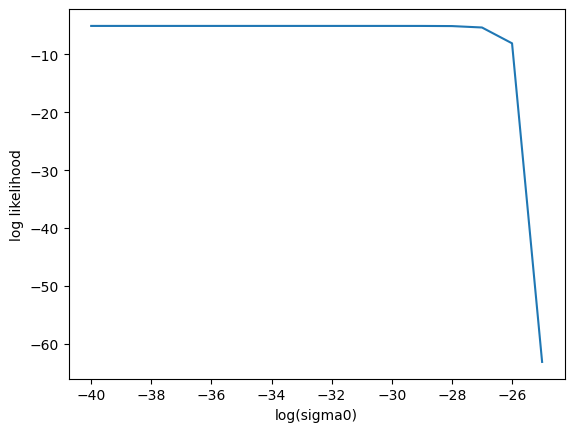

In [165]:
plt.plot(log_sigma0s, log_liks)
plt.xlabel('log(sigma0)')
plt.ylabel('log likelihood')

In [199]:
# for parallelization, check cpus
from multiprocessing import cpu_count

ncpu = cpu_count()
print("{0} CPUs".format(ncpu))

8 CPUs


In [201]:
# prepare MCMC

ndim, nwalkers = 2, 8
initial=np.zeros((nwalkers, ndim ))

# initialize walkers
log_sigma0 = np.random.uniform(low=-40, high=-20, size=nwalkers).astype(np.float128)
log_mp = np.log10(const.m_p.to(u.GeV, equivalencies=u.mass_energy()).value)
log_mx = np.random.uniform(low=-4, high=log_mp, size=nwalkers).astype(np.float128)

initial[:,0]=log_sigma0
initial[:,1]=log_mx
initial

array([[-36.21212917,  -2.58215512],
       [-22.76946344,  -2.13212282],
       [-37.18883723,  -2.45780996],
       [-30.22184506,  -1.50220021],
       [-39.62959818,  -3.04217365],
       [-30.79693468,  -1.76743028],
       [-26.53639324,  -0.65483252],
       [-29.35323366,  -0.57798181]])

In [205]:
# with low agn heating model
with Pool() as pool:
    sampler = emcee.EnsembleSampler(nwalkers,
                                ndim,
                                log_lik,
                                args=[L_obs, nfws_subset, variances_obs, 1])
    state = sampler.run_mcmc(initial, 1000, progress=True)

100%|███████████████████████████████████████| 1000/1000 [39:38<00:00,  2.38s/it]


(528, 2)


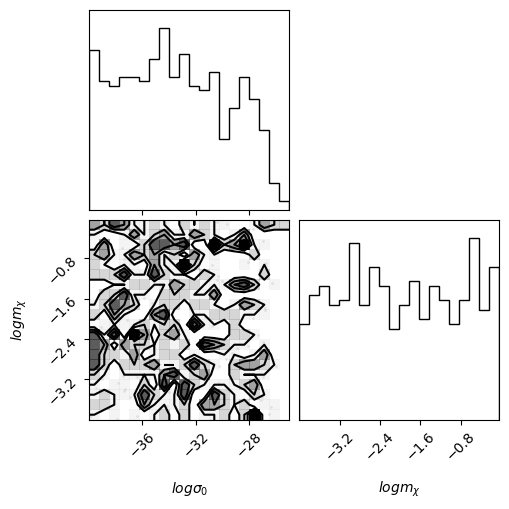

In [206]:
# create corner plot of results
flat_samples = sampler.get_chain(thin=15, flat=True)

print(flat_samples.shape)

labels = [r"$log \sigma_0$", r"$log m_\chi$"]
fig = corner.corner(
    flat_samples, labels=labels
);

In [207]:
with Pool() as pool:
    # start sampler after some steps to minimize dependence on initial conditions
    state_f = sampler.run_mcmc(state, 10000, progress = True)

100%|███████████████████████████████████| 10000/10000 [8:13:28<00:00,  2.96s/it]


(5864, 2)


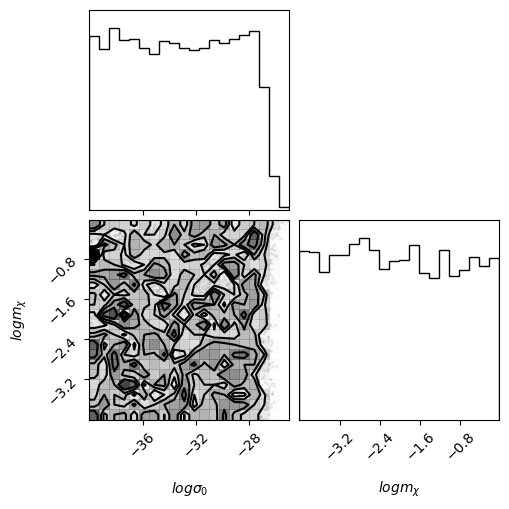

In [208]:
# create corner plot of results
flat_samples = sampler.get_chain(thin=15, flat=True)

print(flat_samples.shape)

labels = [r"$log \sigma_0$", r"$log m_\chi$"]
fig = corner.corner(
    flat_samples, labels=labels
);

In [209]:
np.savez("sampler_state.npz",
         chain=sampler.chain,
         lnprobability=sampler.lnprobability,
         rstate=sampler.random_state,
         acceptance_fraction=sampler.acceptance_fraction)

ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (5,) + inhomogeneous part.

In [227]:
with Pool() as pool:
    state_2 = sampler.run_mcmc(state_f, 10000, progress = True)

100%|███████████████████████████████████| 10000/10000 [6:34:23<00:00,  2.37s/it]


(16528, 2)


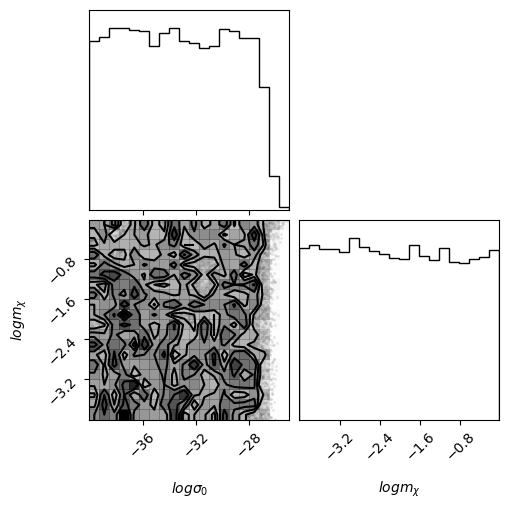

In [233]:
# create corner plot of results
flat_samples2 = sampler.get_chain(thin=15, flat=True)

print(flat_samples2.shape)

labels = [r"$log \sigma_0$", r"$log m_\chi$"]
fig = corner.corner(
    flat_samples2, labels=labels
);

In [231]:
with Pool() as pool:
    state_3 = sampler.run_mcmc(state_f, 10000, progress = True)

100%|██████████████████████████████████| 10000/10000 [13:56:09<00:00,  5.02s/it]


(16528, 2)


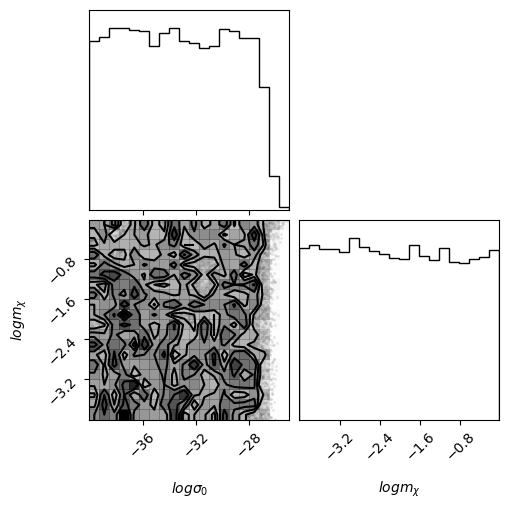

In [235]:
# create corner plot of results
flat_samples3 = sampler.get_chain(thin=15, flat=True)

print(flat_samples3.shape)

labels = [r"$\\mathrm{{log \sigma_0}}$", r"$log m_\chi$"]
fig = corner.corner(
    flat_samples3, labels=labels
);

In [236]:
with Pool() as pool:
    state_4 = sampler.run_mcmc(state_3, 10000, progress = True)

100%|███████████████████████████████████| 10000/10000 [6:25:13<00:00,  2.31s/it]


(21864, 2)


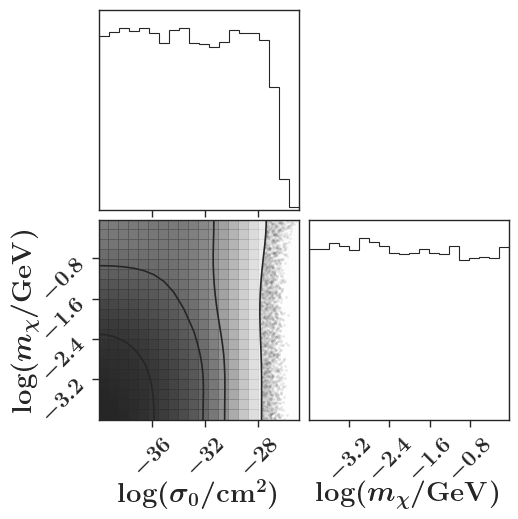

In [263]:
# create corner plot of results
paper_plot()
flat_samples4 = sampler.get_chain(thin=15, flat=True)

print(flat_samples4.shape)

labels = [r"$\mathrm{log} (\sigma_0 / \mathrm{cm^2})$", r"$\mathrm{log} (m_\chi / \mathrm{GeV})$"]
fig = corner.corner(
    flat_samples4, labels=labels, smooth=4
);

fig.savefig('plots/prelim_mcmc.pdf', format='pdf', dpi=450)

In [256]:
with open('mcmc_0001.pkl', 'wb') as g:
    pickle.dump(flat_samples4, g)

In [244]:
nfws_werr_001 = generate_nfws_from_combined_dataset_werr(dataset, variances, rmin=0.001)

In [245]:
nfws_subset_001 = [nfw for nfw in nfws_werr_001 if nfw.z < 0.2]#[:10]
#vars_subset = variances#[:10]
L_obs = np.array([nfw.L500.to(u.erg/u.s).value for nfw in nfws_subset])
variances_obs = np.array([nfw.L_err for nfw in nfws_subset])

In [246]:
with Pool() as pool:
    sampler2 = emcee.EnsembleSampler(nwalkers,
                                ndim,
                                log_lik,
                                args=[L_obs, nfws_subset_001, variances_obs, 1])
    state_001 = sampler2.run_mcmc(initial, 10000, progress=True)

100%|███████████████████████████████████| 10000/10000 [7:44:42<00:00,  2.79s/it]


(4800, 2)


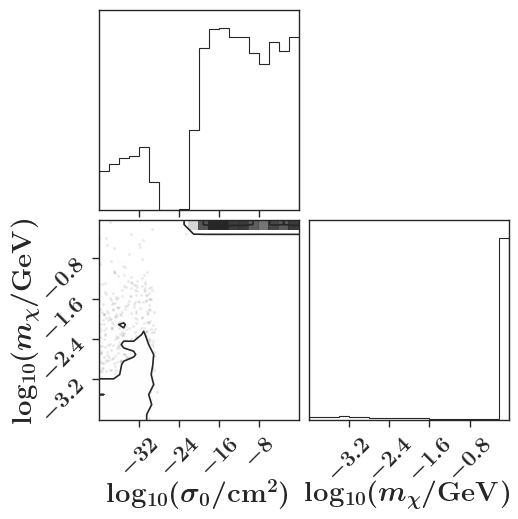

In [405]:
# create corner plot of results
paper_plot()
flat_samples_001 = sampler2.get_chain(discard=1000, thin=15, flat=True)

print(flat_samples_001.shape)

labels = [r"$\mathrm{log_{10}} (\sigma_0 / \mathrm{cm^2})$", r"$\mathrm{log_{10}} (m_\chi / \mathrm{GeV})$"]
fig = corner.corner(
    flat_samples_001, labels=labels, dpi=450, levels=[0.68, 0.95]
);

fig.savefig('plots/mcmc_rmin_1e-3.pdf', format='pdf', dpi=450)

In [408]:
test_nfw = nfws_subset_001[0]

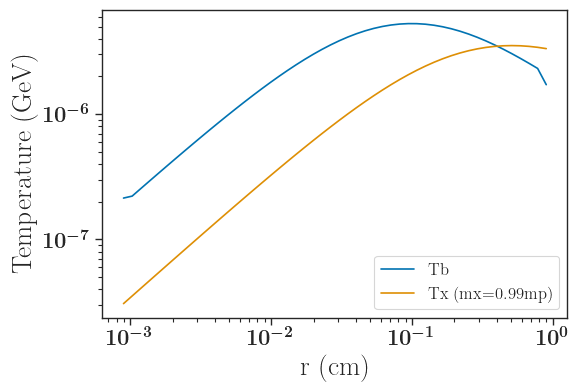

In [422]:
from cluster_error_prop import mp_GeV
test_nfw = nfws_subset_001[0]

plt.loglog(test_nfw.rvals*u.cm.to(u.Mpc), test_nfw.Tbs, label='Tb')
plt.loglog(test_nfw.rvals*u.cm.to(u.Mpc), test_nfw.Tx_by_mx*0.99*mp_GeV, label='Tx (mx=0.99mp)')

plt.ylabel('Temperature (GeV)')
plt.xlabel('r (cm)')
plt.legend()

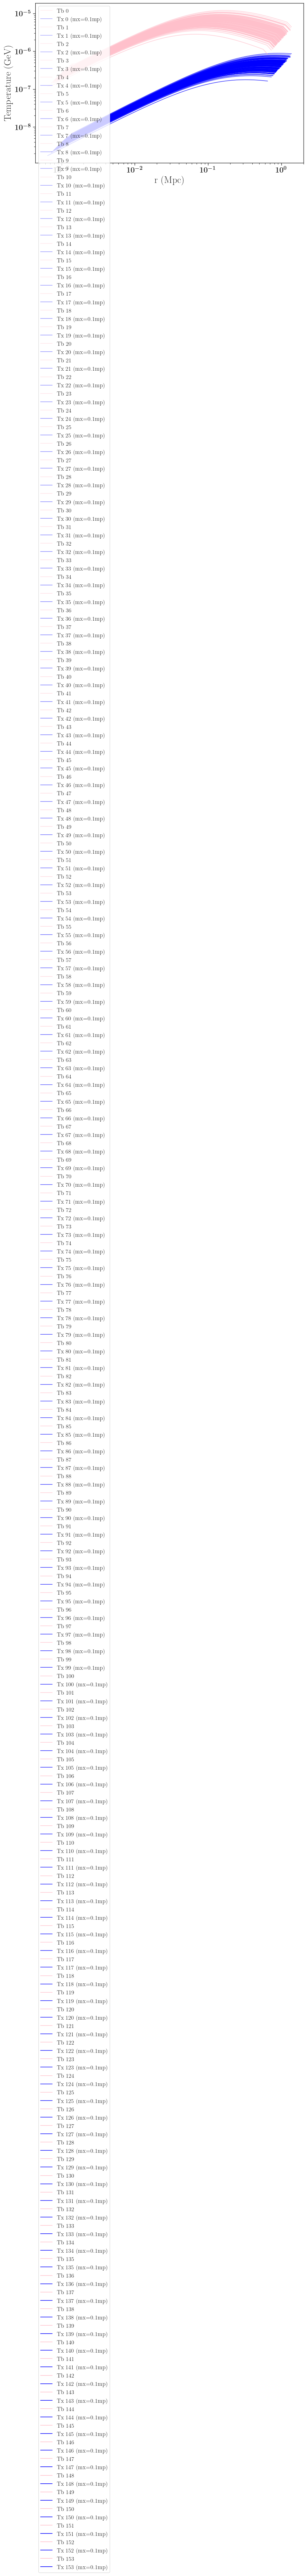

In [432]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.colors as mcolors

fraction_of_mp = 0.1

# Assuming `nfws_subset_001` is a list of data objects similar to `test_nfw`
nfws_subset_001 = [nfw for nfw in nfws_werr_001 if nfw.z < 0.2] # Replace with the actual data

# Define the function to convert color name to RGBA
def to_rgba(color_name, alpha):
    return mcolors.to_rgba(color_name, alpha=alpha)

# Generate shades of blue and pink
blue_colors = [to_rgba('blue', alpha) for alpha in np.linspace(0.3, 1, len(nfws_subset_001))]
pink_colors = [to_rgba('pink', alpha) for alpha in np.linspace(0.3, 1, len(nfws_subset_001))]

plt.figure(figsize=(10, 6))

for i, test_nfw in enumerate(nfws_subset_001):
    rvals_mpc = test_nfw.rvals * u.cm.to(u.Mpc)
    Tb = test_nfw.Tbs
    Tx = test_nfw.Tx_by_mx * fraction_of_mp * mp_GeV

    plt.loglog(rvals_mpc, Tb, label=f'Tb {i}', color=pink_colors[i])
    plt.loglog(rvals_mpc, Tx, label=f'Tx {i} (mx={fraction_of_mp}mp)', color=blue_colors[i])

plt.ylabel('Temperature (GeV)')
plt.xlabel('r (Mpc)')
plt.legend()
plt.show()

(21328, 2)


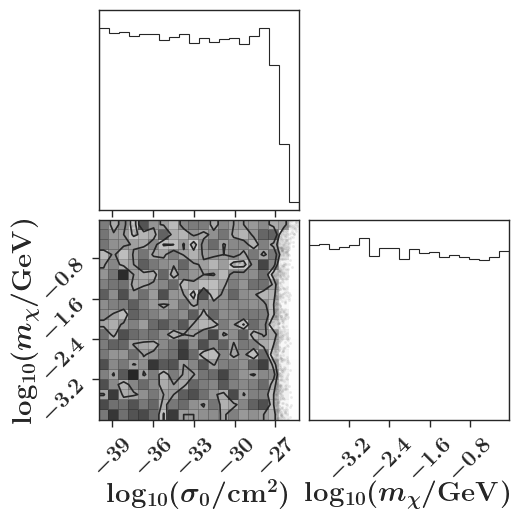

In [407]:
# create corner plot of results
paper_plot()
flat_samples_001 = sampler.get_chain(discard=1000, thin=15, flat=True)

print(flat_samples_001.shape)

labels = [r"$\mathrm{log_{10}} (\sigma_0 / \mathrm{cm^2})$", r"$\mathrm{log_{10}} (m_\chi / \mathrm{GeV})$"]
fig = corner.corner(
    flat_samples_001, labels=labels, dpi=450, levels=[0.68, 0.95]
);

fig.savefig('plots/mcmc_rmin_1e-3.pdf', format='pdf', dpi=450)

In [271]:
flat_samples_001

array([[-30.51700549,  -2.40338396],
       [-37.93441899,  -1.6132325 ],
       [-37.52721793,  -2.63274295],
       ...,
       [-36.39802153,  -0.62862719],
       [-33.57935817,  -3.04755972],
       [-39.16166893,  -3.42639045]])

In [287]:
samples_coords = np.array([[x, y] for y, x in flat_samples_001])
samples_coords

array([[ -2.40338396, -30.51700549],
       [ -1.6132325 , -37.93441899],
       [ -2.63274295, -37.52721793],
       ...,
       [ -0.62862719, -36.39802153],
       [ -3.04755972, -33.57935817],
       [ -3.42639045, -39.16166893]])

In [288]:
samples_coords[:,0]

array([-2.40338396, -1.6132325 , -2.63274295, ..., -0.62862719,
       -3.04755972, -3.42639045])

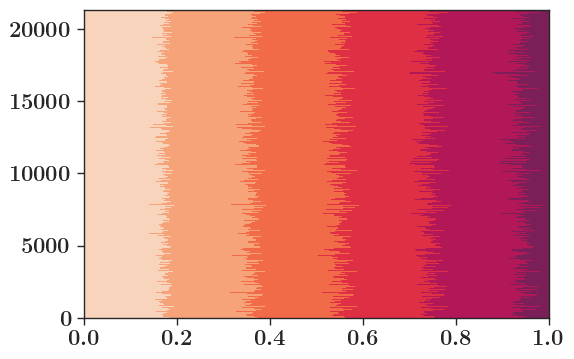

In [274]:
plt.contourf(samples_coords)

/var/folders/99/vfh56jrs1nqcj8zqtcs5fkv40000gn/T/ipykernel_18443/1100074383.py:25: UserWarning: The following kwargs were not used by contour: 'labels'
  contour = plt.contour(X, Y, H_smooth.T, levels=[percentile_value],colors='#1f77b4',labels='this work' )


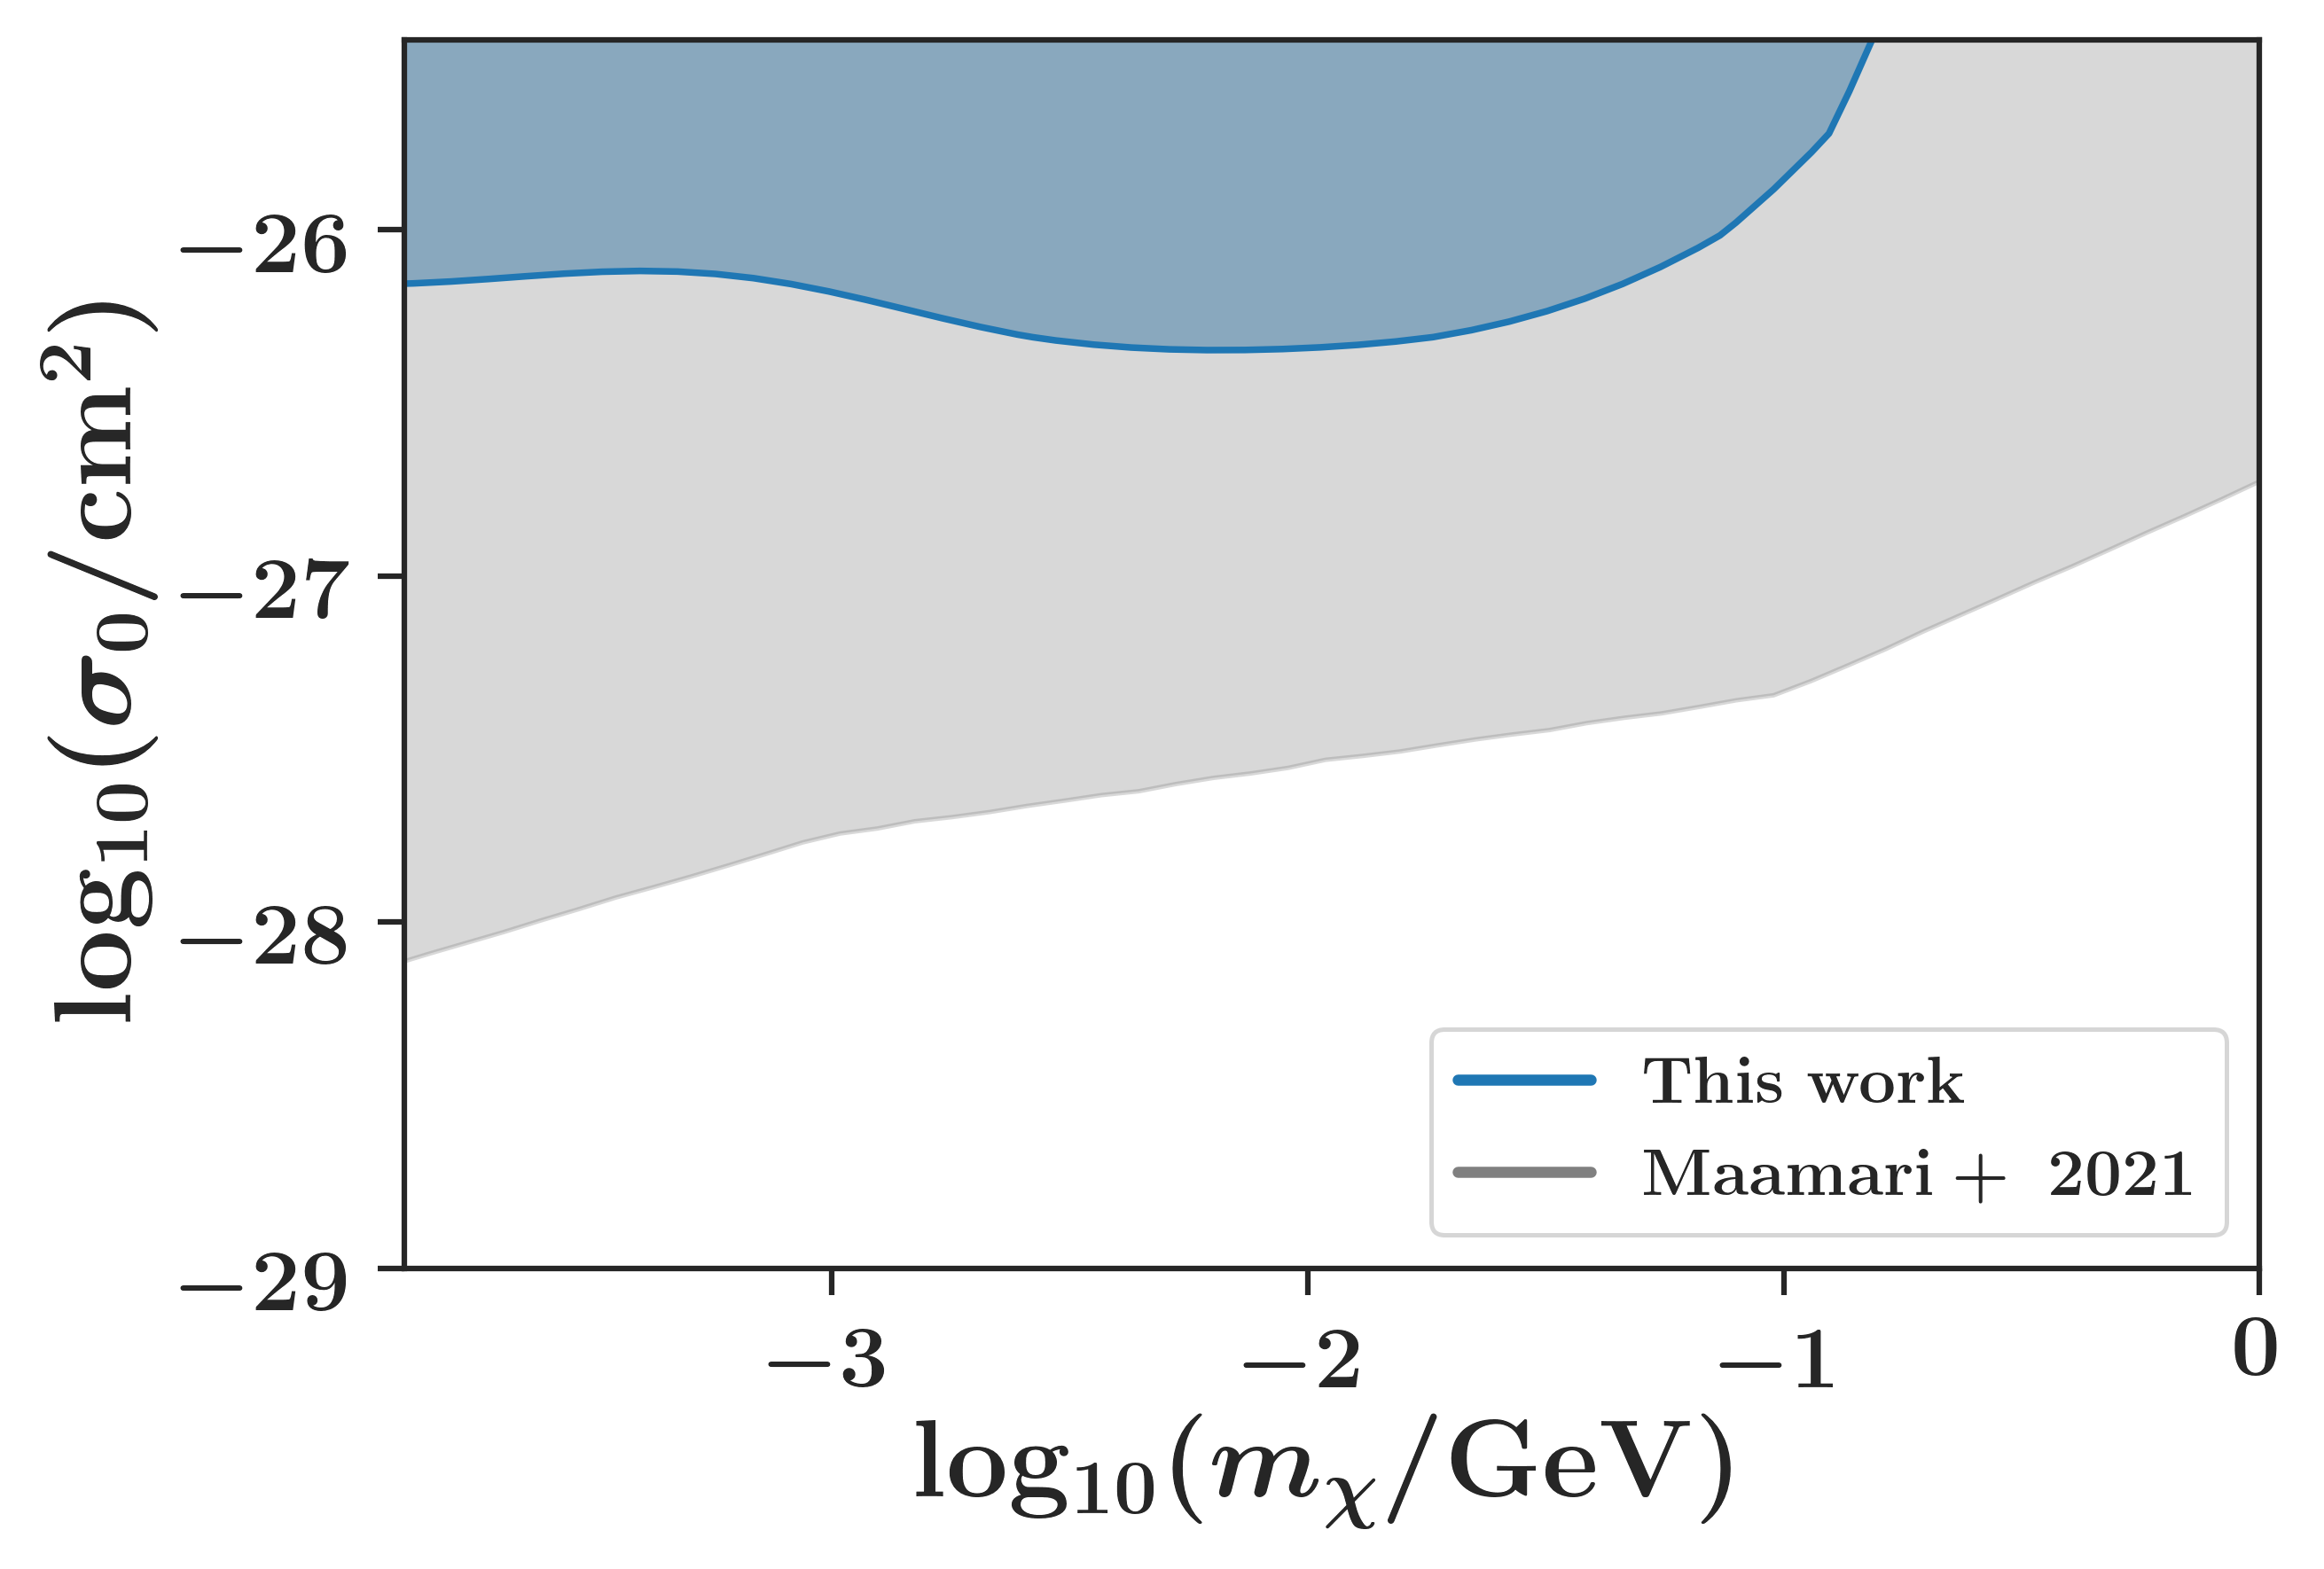

In [401]:
import scipy
from matplotlib.lines import Line2D

# Reshape to get a 2D array of samples
x_samples = samples_coords[:,0]
y_samples = samples_coords[:,1]

# Create a 2D histogram
nbins = 50
H, xedges, yedges = np.histogram2d(x_samples, y_samples, bins=nbins, density=True)

# Apply Gaussian smoothing
sigma = 5
H_smooth = scipy.ndimage.gaussian_filter(H, sigma=sigma)

# Compute the bin centers
xcenters = (xedges[:-1] + xedges[1:]) / 2
ycenters = (yedges[:-1] + yedges[1:]) / 2

# Find the 95th percentile value
percentile_value = np.percentile(H_smooth, 5)

# Generate the contour plot
plt.figure(dpi=450)#(figsize=(8, 6))
contour = plt.contour(X, Y, H_smooth.T, levels=[percentile_value],colors='#1f77b4',labels='this work' )
#plt.colorbar(contour, label='Density')
plt.contourf(X, Y, H_smooth.T, levels=[0, percentile_value], alpha=0.5,colors='#1f77b4')

#plt.clabel(contour)
handles=[Line2D([0], [0], color='#1f77b4', lw=2, label=f'$\mathrm{{This~work}}$'),
        Line2D([0], [0], color='gray', lw=2, label=f"$\mathrm{{Maamari+~2021}}$")]

plt.xlim(-4, 0)
#plt.ylim(-30, -25.5)

import pandas as pd
maamari = pd.read_csv('data/maamari_2021_constraint.csv', header=None)
plt.plot(maamari[0], maamari[1], label=f"$\mathrm{{Maamari+ 2021}}$", color='gray')

plt.legend(handles=handles, loc='lower right')
#plt.xlabel(r"$m_{\chi} \mathrm{(GeV)}$")
#plt.ylabel(r"$\sigma_0 (\mathrm{cm}^2)$")
plt.xlabel("DM particle mass (GeV)")
plt.ylabel(r"Interaction cross section (cm$^2$)")

plt.fill_between(
                    np.log10(maamari[0]), np.log10(maamari[1]),
                    y2=1e-26,
                    alpha=0.3, color='gray'
                )

# Customize the plot
#plt.title('95th Percentile Contour Plot')
plt.xlabel(r"$\mathrm{log_{10}} (m_\chi / \mathrm{GeV})$")
plt.ylabel(r"$\mathrm{log_{10}} (\sigma_0 / \mathrm{cm^2})$")

# Show the plot

plt.xlim(-3.9, 0)
plt.ylim(-29, -25.45)
plt.show()

In [249]:
type(flat_samples_001)

numpy.ndarray

In [251]:
import pickle
with open('mcmc_001.pkl', 'wb') as f:
    pickle.dump(flat_samples_001, f)